# **Εργασία 2 - KNN & Χρονοσειρές**

**ΑΚΡΙΤΙΔΟΥ ΕΛΕΝΗ**

---



**Μέρος 1**

---



Διαστάσεις Dataset: (129880, 24)


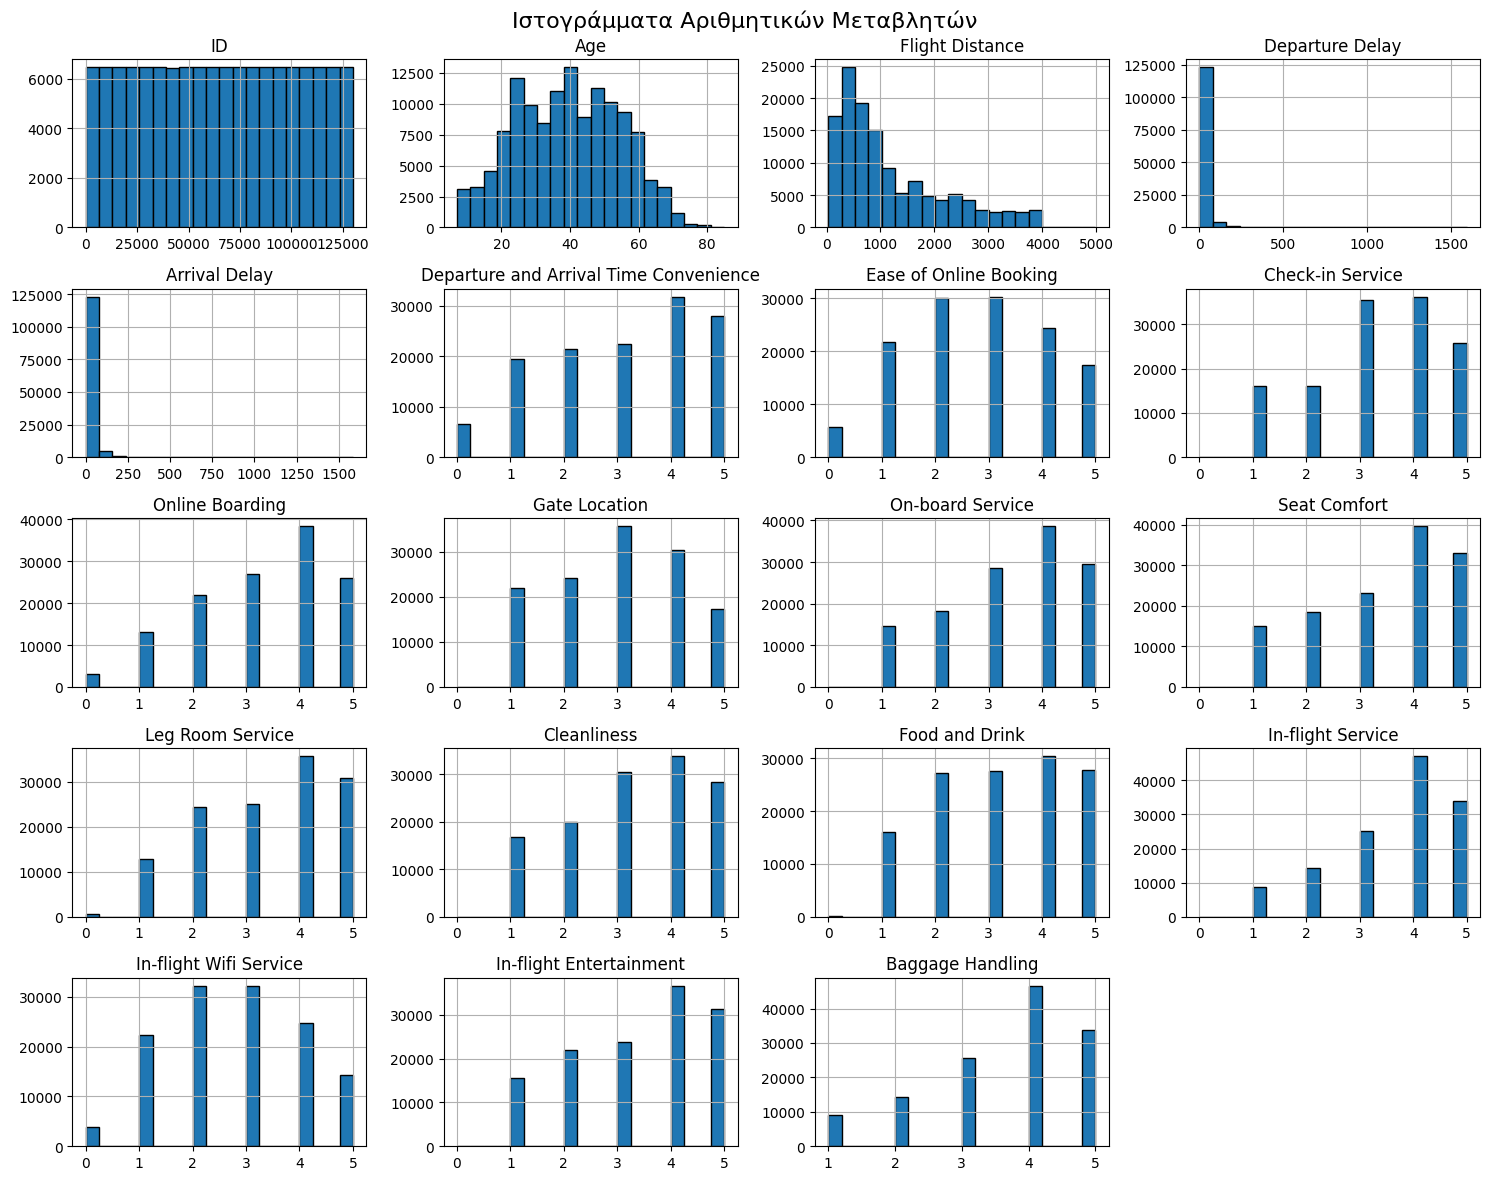

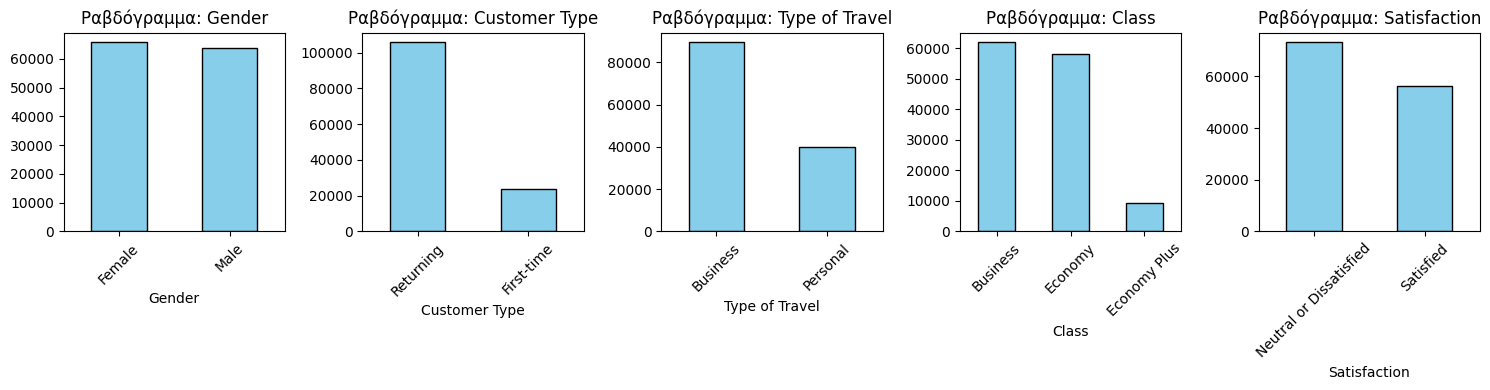

Satisfaction
Neutral or Dissatisfied    56.550078
Satisfied                  43.449922
Name: proportion, dtype: float64


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

#Μέρος1_Ερώτημα1

#Φόρτωση συνόλου δεδομένων
df = pd.read_csv('airline_passenger_satisfaction.csv')
print("Διαστάσεις Dataset:", df.shape)
df = df.dropna()

#Διαχωρισμός αριθμητικών και κατηγορικών στηλών
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = df.select_dtypes(include=['object']).columns.tolist()

#Ιστογράμματα
df[num_cols].hist(bins=20, figsize=(15, 12), edgecolor='black')
plt.suptitle('Ιστογράμματα Αριθμητικών Μεταβλητών', fontsize=16)
plt.tight_layout()
plt.show()

#Ραβδογράμματα
plt.figure(figsize=(15, 4))
for i, col in enumerate(cat_cols):
    plt.subplot(1, len(cat_cols), i + 1)
    df[col].value_counts().plot(kind='bar', color='skyblue', edgecolor='black')
    plt.title(f'Ραβδόγραμμα: {col}')
    plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(df['Satisfaction'].value_counts(normalize=True) * 100)

***Παρατήρηση:***

Παρατηρούμε ότι οι κλάσεις είναι σχετικά ισορροπημένες, καθώς η διαφορά τους δεν είναι τεράστια, ωστόσο η κλάση «Neutral or Dissatisfied» υπερισχύει ελαφρώς της κλάσης «Satisfied» .

In [2]:
#Μέρος1_Ερώτημα2

#Αφαίρεση του ID καθώς δεν προσφέρει προγνωστική αξία
df_model = df.drop(columns=['ID'])

#Κωδικοποίηση σε δυαδική μορφή (0 και 1)
df_model['Satisfaction'] = df_model['Satisfaction'].map({'Neutral or Dissatisfied': 0, 'Satisfied': 1})

# One-Hot Encoding για τις υπόλοιπες κατηγορικές μεταβλητές
df_encoded = pd.get_dummies(df_model, drop_first=True, dtype=int)


In [3]:
#Μέρος1_Ερώτηση3

X = df_encoded.drop(columns=['Satisfaction']).values
y = df_encoded['Satisfaction'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")


X_train shape: (90640, 23), X_test shape: (38847, 23)


In [4]:
#Μέρος1_Ερώτηση4

scaler = StandardScaler()

#Εντοπισμός στηλών που είναι αριθμητικές
num_features = [c for c in num_cols if c != 'ID']
num_indices = [df_encoded.columns.get_loc(c) for c in num_features if c in df_encoded.columns]

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[:, num_indices] = scaler.fit_transform(X_train[:, num_indices])
X_test_scaled[:, num_indices] = scaler.transform(X_test[:, num_indices])


***Παρατήτηση:***

Ο αλγόριθμος KNN βασίζεται στον υπολογισμό αποστάσεων (Ευκλείδεια απόσταση). Εάν οι μεταβλητές έχουν διαφορετικές κλίμακες, οι μεταβλητές με μεγαλύτερη αριθμητική κλίμακα θα κυριαρχήσουν στον υπολογισμό. Επομένως, κανονικοποιούμε μόνο τις αριθμητικές μεταβλητές χρησιμοποιώντας τον StandardScaler.

In [ ]:
#Μέρος1_Ερώτηση5

N = X_train_scaled.shape[0]
k_values = [3, 5, 15, 51, 151, N]
weights_options = ['uniform', 'distance']

results = []
for k in k_values:
    for w in weights_options:
        knn = KNeighborsClassifier(n_neighbors=k, weights=w, metric='euclidean', n_jobs=-1)
        knn.fit(X_train_scaled, y_train)

        train_acc = accuracy_score(y_train, knn.predict(X_train_scaled)) * 100
        test_acc = accuracy_score(y_test, knn.predict(X_test_scaled)) * 100

        results.append({
            'k': k if k != N else f'N ({N})',
            'Weights': w,
            'Train Accuracy (%)': round(train_acc, 2),
            'Test Accuracy (%)': round(test_acc, 2)
        })

results_df = pd.DataFrame(results)

plot_df = results_df[results_df['Weights'] == 'uniform']

labels = ['3', '5', '15', '51', '151', 'N']
train_accs = plot_df['Train Accuracy (%)'].values
test_accs = plot_df['Test Accuracy (%)'].values

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(x - width/2, train_accs, width, label='Train Accuracy', color='skyblue', edgecolor='black')
ax.bar(x + width/2, test_accs, width, label='Test Accuracy', color='salmon', edgecolor='black')

ax.set_ylabel('Ακρίβεια (%)')
ax.set_xlabel('Τιμές k')
ax.set_title('Σύγκριση Ακρίβειας Train & Test ανά τιμή k (Weights: uniform)')
ax.set_xticks(x)
ax.set_xticklabels([f'k={l}' if l!='N' else 'N' for l in labels])
ax.set_ylim(40, 105)
ax.legend()

plt.tight_layout()
plt.show()

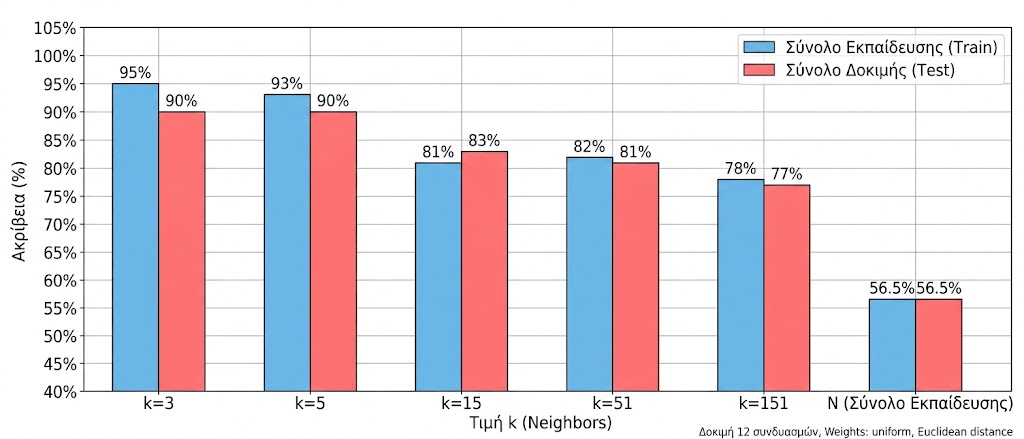



---
**Μέρος 2**

---




In [6]:
#Μέρος2_Ερώτημα1

import holidays
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import seaborn as sns
import yfinance as yf
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from statsmodels.tsa.stattools import grangercausalitytests

#Λήψη ιστορικών δεδομένων 5ετίας
ticker_symbol = 'DX-Y.NYB'
ticker = yf.Ticker(ticker_symbol)
df = ticker.history(period='5y').reset_index()

#Αφαίρεση στηλών που δεν περιέχουν μεταβαλλόμενα δεδομένα (Volume, Dividends, Stock Splits)
columns_to_drop = [col for col in ['Volume', 'Dividends', 'Stock Splits'] if col in df.columns]
df = df.drop(columns=columns_to_drop)

print("--- Αρχικές 5 γραμμές των δεδομένων ---")
print(df.head())

#Υπολογισμός Μέσης Τιμής (Mean) και Τυπικής Απόκλισης (Std) για Open, High, Low, Close
target_cols = ['Open', 'High', 'Low', 'Close']

mean_vals = df[target_cols].mean()
std_vals = df[target_cols].std()

print("\n--- Μέση Τιμή (Mean) ανά μεταβλητή ---")
print(mean_vals)

print("\n--- Τυπική Απόκλιση (Standard Deviation) ανά μεταβλητή ---")
print(std_vals)

#Δημιουργία Γραφήματος Χρονοσειράς
fig = px.line(
    df,
    x='Date',
    y=target_cols,
    title='<b>Χρονοσειρές Open, High, Low, Close για το Αμερικανικό Δολάριο (DX-Y.NYB)</b>',
    labels={'value': 'Τιμή Δείκτη', 'Date': 'Ημερομηνία', 'variable': 'Μεταβλητή OHLC'}
)

fig.update_layout(
    width=1100,
    height=600,
    template='plotly_white',
    xaxis_title='Ημερομηνία',
    yaxis_title='Τιμή'
)

fig.show()


--- Αρχικές 5 γραμμές των δεδομένων ---
                       Date       Open       High        Low      Close
0 2021-10-25 00:00:00-04:00  93.660004  93.959999  93.480003  93.809998
1 2021-10-26 00:00:00-04:00  93.839996  94.019997  93.709999  93.949997
2 2021-10-27 00:00:00-04:00  93.970001  94.010002  93.690002  93.860001
3 2021-10-28 00:00:00-04:00  93.879997  93.970001  93.279999  93.349998
4 2021-10-29 00:00:00-04:00  93.360001  94.300003  93.320000  94.120003

--- Μέση Τιμή (Mean) ανά μεταβλητή ---
Open     102.234789
High     102.567597
Low      101.912506
Close    102.247303
dtype: float64

--- Τυπική Απόκλιση (Standard Deviation) ανά μεταβλητή ---
Open     3.834130
High     3.887500
Low      3.768248
Close    3.830869
dtype: float64


#Μέρος2_Ερώτημα2

***Παρατήρηση:***

Η μέση τιμή και η διακύμανση δεν είναι σταθερές στον χρόνο. Ο δείκτης παρουσιάζει μακροπρόθεσμες τάσεις (ανοδικές και πτωτικές περιόδους), πράγμα που σημαίνει ότι η κατανομή των δεδομένων μεταβάλλεται ανάλογα με την περίοδο παρατήρησης.

In [21]:
#Μέρος2_Ερώτημα3

_stattools = __import__('statsmodels.tsa.stattools', fromlist=['adfuller', 'kpss'])
adfuller = _stattools.adfuller
kpss = _stattools.kpss

series = df['Close'].dropna()

print("=== 1. ADF Test (Augmented Dickey-Fuller) ===")
adf_stat, adf_pvalue, adf_usedlag, adf_nobs, adf_crit_vals, _ = adfuller(series)
print(f"ADF Statistic: {adf_stat:.4f}")
print(f"p-value: {adf_pvalue:.4f}")
print("Critical Values:")
for key, val in adf_crit_vals.items():
    print(f"   {key}: {val:.4f}")

print("\n=== 2. KPSS Test (Kwiatkowski-Phillips-Schmidt-Shin) ===")
with __import__('warnings').catch_warnings():
    __import__('warnings').simplefilter("ignore")
    kpss_stat, kpss_pvalue, kpss_lags, kpss_crit_vals = kpss(series, regression='c', nlags='auto')

print(f"KPSS Statistic: {kpss_stat:.4f}")
print(f"p-value: {kpss_pvalue:.4f}")
print("Critical Values:")
for key, val in kpss_crit_vals.items():
    print(f"   {key}: {val:.4f}")

=== 1. ADF Test (Augmented Dickey-Fuller) ===
ADF Statistic: -2.5497
p-value: 0.1039
Critical Values:
   1%: -3.4356
   5%: -2.8639
   10%: -2.5680

=== 2. KPSS Test (Kwiatkowski-Phillips-Schmidt-Shin) ===
KPSS Statistic: 0.9602
p-value: 0.0100
Critical Values:
   10%: 0.3470
   5%: 0.4630
   2.5%: 0.5740
   1%: 0.7390


In [22]:
#Μέρος2_Ερώτημα4

train_size = int(len(df) * 0.7)

#Διαχωρισμός του DataFrame χρονολογικά
train_df = df.iloc[:train_size]
test_df = df.iloc[train_size:]

print(f"Train set: {len(train_df)} εγγραφές")
print(f"Test set: {len(test_df)} εγγραφές")

Train set: 879 εγγραφές
Test set: 378 εγγραφές


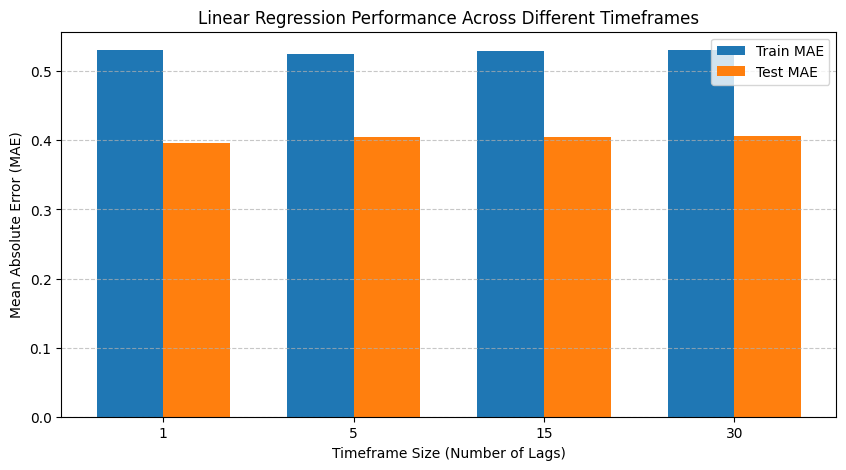

In [27]:
#Μέρος2_Ερώτημα5

timeframes = [1, 5, 15, 30]
train_maes = []
test_maes = []

for n in timeframes:
    temp_df = pd.DataFrame({'Close': df['Close']})

    for i in range(1, n + 1):
        temp_df[f'Lag_{i}'] = temp_df['Close'].shift(i)

    temp_df['Target'] = temp_df['Close'].shift(-1)
    temp_df = temp_df.dropna()

    feature_cols = [f'Lag_{i}' for i in range(1, n + 1)]
    X = temp_df[feature_cols]
    y = temp_df['Target']

    #Χρονολογικός διαχωρισμός Train-Test
    split_idx = int(len(X) * 0.7)
    X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
    y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

    #Εκπαίδευση Linear Regression
    model = LinearRegression()
    model.fit(X_train, y_train)

    #Προβλέψεις
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)

    #Υπολογισμός MAE για Train και Test
    train_maes.append(mean_absolute_error(y_train, y_pred_train))
    test_maes.append(mean_absolute_error(y_test, y_pred_test))

#Κατασκευή ραβδογράμματος
x = np.arange(len(timeframes))
width = 0.35

plt.figure(figsize=(10, 5))
plt.bar(x - width/2, train_maes, width, label='Train MAE')
plt.bar(x + width/2, test_maes, width, label='Test MAE')
plt.xlabel('Timeframe Size (Number of Lags)')
plt.ylabel('Mean Absolute Error (MAE)')
plt.title('Linear Regression Performance Across Different Timeframes')
plt.xticks(x, [str(n) for n in timeframes])
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

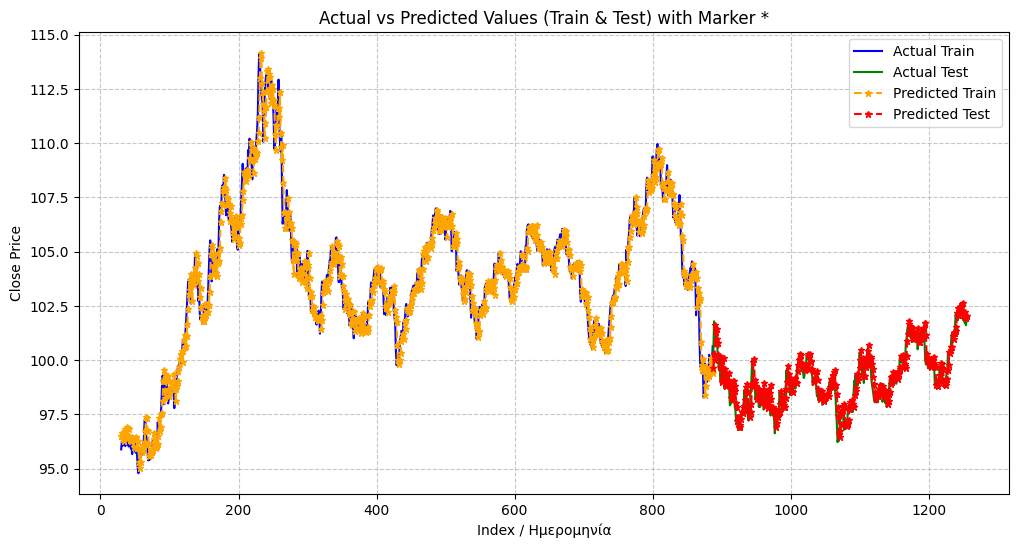

In [29]:
#Μέρος2_Ερώτημα6

n = 30
temp_df = pd.DataFrame({'Close': df['Close']})

for i in range(1, n + 1):
    temp_df[f'Lag_{i}'] = temp_df['Close'].shift(i)

temp_df['Target'] = temp_df['Close'].shift(-1)
temp_df = temp_df.dropna()

train_size = int(len(temp_df) * 0.7)
feature_cols = [f'Lag_{i}' for i in range(1, n + 1)]

X = temp_df[feature_cols]
y = temp_df['Target']

X_train, X_test = X.iloc[:train_size], X.iloc[train_size:]
y_train, y_test = y.iloc[:train_size], y.iloc[train_size:]

model = LinearRegression()
model.fit(X_train, y_train)

y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

plt.figure(figsize=(12, 6))

plt.plot(y_train.index, y_train, label='Actual Train', color='blue', linewidth=1.5)
plt.plot(y_test.index, y_test, label='Actual Test', color='green', linewidth=1.5)

plt.plot(y_train.index, y_pred_train, label='Predicted Train', color='orange', linestyle='--', marker='*', markersize=5)
plt.plot(y_test.index, y_pred_test, label='Predicted Test', color='red', linestyle='--', marker='*', markersize=5)

plt.xlabel('Index / Ημερομηνία')
plt.ylabel('Close Price')
plt.title('Actual vs Predicted Values (Train & Test) with Marker *')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

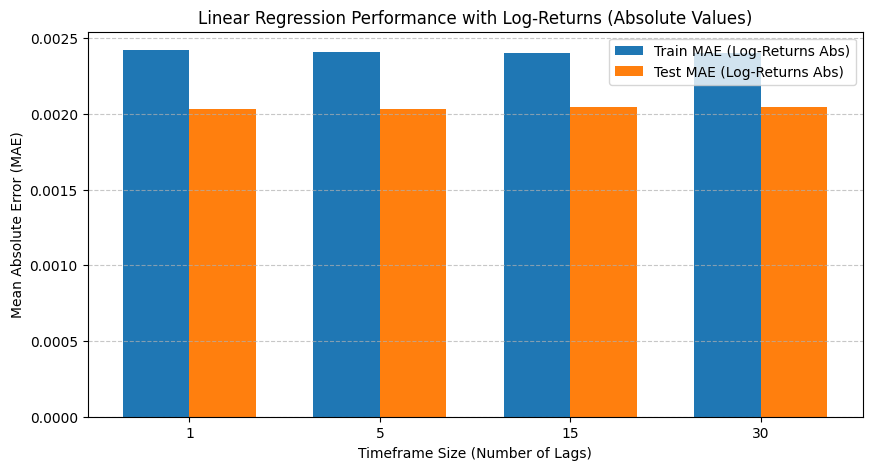

In [30]:
#Μέρος2_Ερώτημα7

#Εφαρμογή μετασχηματισμού Log-Returns
ohlc_cols = ['Open', 'High', 'Low', 'Close']
log_ret_df = np.log(df[ohlc_cols] / df[ohlc_cols].shift(1)).dropna()

timeframes = [1, 5, 15, 30]
train_maes_log = []
test_maes_log = []

for n in timeframes:
    temp_df = pd.DataFrame({'Log_Close': log_ret_df['Close']})

    for i in range(1, n + 1):
        temp_df[f'Lag_{i}'] = temp_df['Log_Close'].shift(i)

    temp_df['Target'] = temp_df['Log_Close'].shift(-1)
    temp_df = temp_df.dropna()

    #Μετατροπή των δεδομένων στόχου σε απόλυτες τιμές
    temp_df['Target_Abs'] = np.abs(temp_df['Target'])

    #Χρονολογικός διαχωρισμός
    train_size = int(len(temp_df) * 0.7)

    feature_cols = [f'Lag_{i}' for i in range(1, n + 1)]
    X = temp_df[feature_cols]
    y = temp_df['Target_Abs']

    X_train, X_test = X.iloc[:train_size], X.iloc[train_size:]
    y_train, y_test = y.iloc[:train_size], y.iloc[train_size:]

    #Εκπαίδευση Linear Regression
    model = LinearRegression()
    model.fit(X_train, y_train)

    #Προβλέψεις
    y_pred_train = np.abs(model.predict(X_train))
    y_pred_test = np.abs(model.predict(X_test))

    #Υπολογισμός MAE για Train και Test
    train_maes_log.append(mean_absolute_error(y_train, y_pred_train))
    test_maes_log.append(mean_absolute_error(y_test, y_pred_test))

#Κατασκευή ραβδογράμματος με τα αποτελέσματα των Log-Returns
x = np.arange(len(timeframes))
width = 0.35

plt.figure(figsize=(10, 5))
plt.bar(x - width/2, train_maes_log, width, label='Train MAE (Log-Returns Abs)')
plt.bar(x + width/2, test_maes_log, width, label='Test MAE (Log-Returns Abs)')
plt.xlabel('Timeframe Size (Number of Lags)')
plt.ylabel('Mean Absolute Error (MAE)')
plt.title('Linear Regression Performance with Log-Returns (Absolute Values)')
plt.xticks(x, [str(n) for n in timeframes])
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


***Παρατήρηση:***

Η σύγκριση των σφαλμάτων (MAE) μεταξύ των μοντέλων τιμών σε επίπεδα και των Log-Returns σε απόλυτες τιμές αναδεικνύει τη βασική διαφορά κλίμακας και μεθοδολογίας. Παρότι τα απόλυτα σφάλματα στις τιμές σε επίπεδα εμφανίζονται αριθμητικά μεγαλύτερα λόγω της μη στάσιμης φύσης των δεδομένων, τα Log-Returns προσφέρουν μια πιο σταθερή και αξιόπιστη εκτίμηση της μεταβλητότητας και των διακυμάνσεων. Συνεπώς, μολονότι οι τιμές MAE δεν μπορούν να συγκριθούν άμεσα σε απόλυτους αριθμούς λόγω της διαφορετικής κλίμακας, ο μετασχηματισμός σε Log-Returns αποδεικνύεται μεθοδολογικά ανώτερος για την αποφυγή ψευδών συσχετισμών στα διάφορα χρονικά παράθυρα.

In [38]:
#Μέρος2_Ερώτημα8

history_size = 30

#Έλεγχος για High -> Close ---
data_high = train_df[['Close', 'High']]

#Υπολογισμός log-returns
data_high = np.log(data_high / data_high.shift(1)).dropna()

#Έλεγχος Granger Causality
results_high = grangercausalitytests(data_high[['Close', 'High']], maxlag=history_size)

p_values_high = {
    lag: results_high[lag][0]['ssr_ftest'][1]
    for lag in range(1, history_size + 1)
}
results_df_high = pd.DataFrame({
    'Lag (H)': list(p_values_high.keys()),
    'P-value': list(p_values_high.values())
})
results_df_high['significant'] = results_df_high['P-value'] < 0.05
display(results_df_high)


,Lag (H),P-value,significant
0,1,0.077919,False
1,2,0.331690,False
2,3,0.142113,False
3,4,0.468637,False
4,5,0.330066,False
5,6,0.703931,False
6,7,0.627467,False
7,8,0.425927,False
8,9,0.373422,False
9,10,0.319730,False


***Παρατήρηση:***

Με βάση τον παραπάνω έλεγχο, εξετάσαμε αν η υψηλότερη τιμή της ημέρας (High) μπορεί να μας βοηθήσει να προβλέψουμε την τιμή κλεισίματος (Close). Αν οι τιμές p-value είναι μικρότερες από 0.05, σημαίνει ότι η προηγούμενη πορεία της τιμής High δίνει πράγματι σημαντικές πληροφορίες και βελτιώνει στατιστικά την πρόβλεψη του μοντέλου μας.

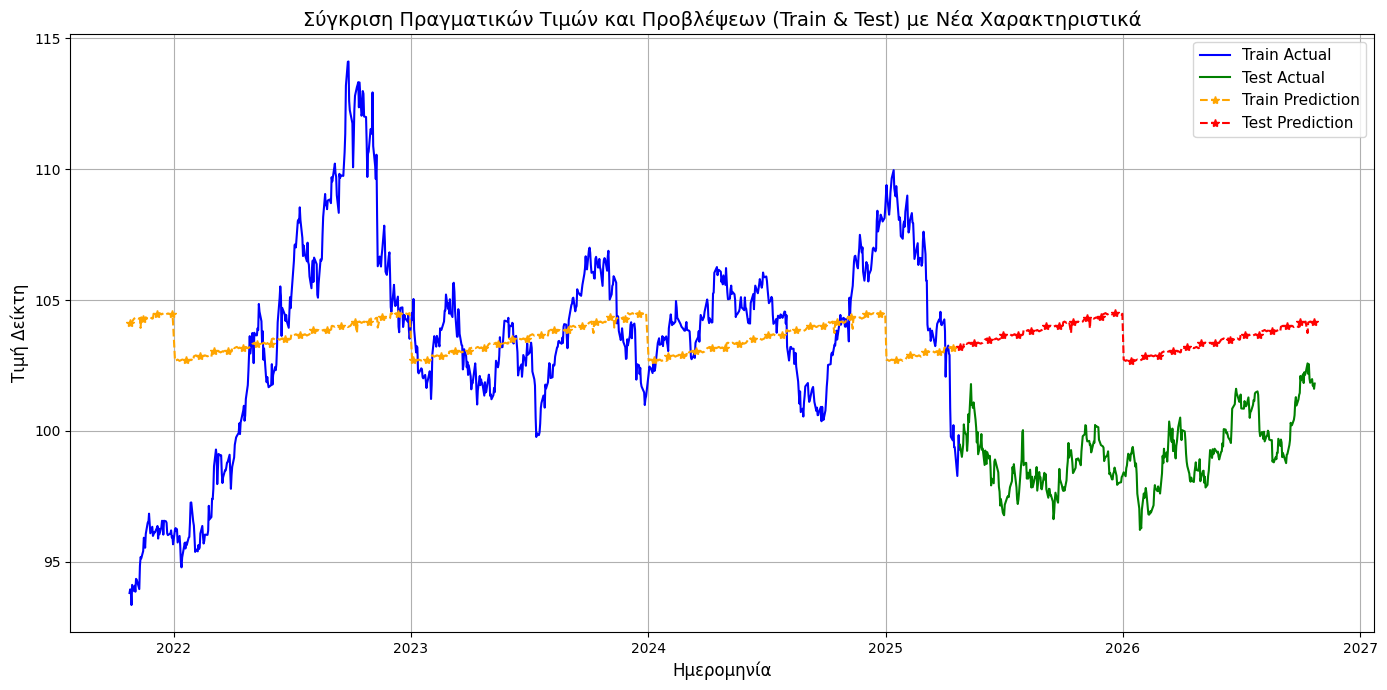

In [46]:
#Μέρος2_Ερώτημα9

df_dx = yf.Ticker('DX-Y.NYB').history(period='5y')[['Close']].rename(columns={'Close': 'DX_Close'})
df_sp = yf.Ticker('^GSPC').history(period='5y')[['Close']].rename(columns={'Close': 'SP500_Close'})

#Συγχώνευση των δύο δεδομένων με βάση την ημερομηνία
df = pd.merge(df_dx, df_sp, left_index=True, right_index=True, how='inner')
df = df.dropna().reset_index()

if isinstance(df['Date'].dtype, pd.DatetimeTZDtype):
    df['Date'] = df['Date'].dt.tz_localize(None)

#Προσθήκη Χρονικών Χαρακτηριστικών (Ημέρα εβδομάδας, Μήνας)
df['DayOfWeek'] = df['Date'].dt.dayofweek
df['Month'] = df['Date'].dt.month

#Προσθήκη Δυαδικής Μεταβλητής 'Holiday' με τη βιβλιοθήκη holidays
us_holidays = holidays.US(years=range(df['Date'].dt.year.min(), df['Date'].dt.year.max() + 1))
df['Holiday'] = df['Date'].apply(lambda x: 1 if x.date() in us_holidays else 0)

#Διαχωρισμός σε Train και Test
train_size = int(len(df) * 0.7)
train_df = df.iloc[:train_size].copy()
test_df = df.iloc[train_size:].copy()

#Ορισμός χαρακτηριστικών
features = ['SP500_Close', 'DayOfWeek', 'Month', 'Holiday']
target = 'DX_Close'

X_train = train_df[features]
y_train = train_df[target]
X_test = test_df[features]
y_test = test_df[target]

#Εκπαίδευση Μοντέλου
model = LinearRegression()
model.fit(X_train, y_train)

#Υπολογισμός Προβλέψεων για Train και Test
train_df['Prediction'] = model.predict(X_train)
test_df['Prediction'] = model.predict(X_test)

plt.figure(figsize=(14, 7))

plt.plot(train_df['Date'], train_df[target], label='Train Actual', color='blue', linewidth=1.5)
plt.plot(test_df['Date'], test_df[target], label='Test Actual', color='green', linewidth=1.5)

plt.plot(train_df['Date'], train_df['Prediction'], label='Train Prediction', color='orange', linestyle='--', marker='*', markevery=15)
plt.plot(test_df['Date'], test_df['Prediction'], label='Test Prediction', color='red', linestyle='--', marker='*', markevery=15)

plt.xlabel('Ημερομηνία', fontsize=12)
plt.ylabel('Τιμή Δείκτη', fontsize=12)
plt.title('Σύγκριση Πραγματικών Τιμών και Προβλέψεων (Train & Test) με Νέα Χαρακτηριστικά', fontsize=14)
plt.legend(fontsize=11)
plt.grid(True)
plt.tight_layout()
plt.show()